In [1]:
import pandas as pd
import numpy as np
from lifelines import CoxTimeVaryingFitter, KaplanMeierFitter

def build_features(df):
    """
    df columns:
    - car_id
    - month
    - mileage
    - repair_cost
    - major_failure (0/1)
    """
    df = df.sort_values(["car_id", "month"])

    df["cost_6mo"] = (
        df.groupby("car_id")["repair_cost"]
          .rolling(6, min_periods=1).sum()
          .reset_index(level=0, drop=True)
    )

    df["cost_slope"] = (
        df.groupby("car_id")["repair_cost"]
          .rolling(6)
          .apply(lambda x: np.polyfit(range(len(x)), x, 1)[0]
                 if len(x) > 2 else 0)
          .reset_index(level=0, drop=True)
    )

    df["fail_rate"] = (
        df.groupby("car_id")["major_failure"]
          .rolling(12, min_periods=1).mean()
          .reset_index(level=0, drop=True)
    )

    return df

def economic_eol_flag(df, value_func, tau=0.7):
    """
    value_func: callable(t) -> vehicle value
    """
    df["econ_ratio"] = df["cost_6mo"] / df["month"].map(value_func)
    df["econ_eol"] = (df["econ_ratio"] > tau).astype(int)
    return df


def fit_mechanical_hazard(df):
    """
    Requires:
    - start, stop
    - event_mech (1 if mechanical death)
    """
    ctv = CoxTimeVaryingFitter()
    ctv.fit(
        df,
        id_col="car_id",
        start_col="start",
        stop_col="stop",
        event_col="event_mech",
        formula="cost_slope + fail_rate + mileage"
    )
    return ctv

def combined_eol_probability(h_mech, p_econ):
    """
    Competing risks approximation
    """
    return 1 - (1 - h_mech) * (1 - p_econ)




## Assumptions
- Cars have health $H_t$
- Observed maintenance events and costs
- A vehicle value curve exists
- There exists two competeting EOL factors (mechanical, cost)
    - Mechanical = increased failure rate, repairs needed
    - Economic = Rolling repair costs exceed value of vehicle

### Global Variables 

| Term | Definition |
|------|------|
| $H_t$ | Vehicle health $\in (0,1]$|
| $D_t$ | Total deterioration $\in (0, 1]$|
| $f_t$ | Total failure |
| $\tau$| failure tolerence $\in (0, 1]$|
| $\phi$| Decision maker tolerence for cost $\in (0, 1]$|
| $\epsilon, \xi$| Noise/error of model|

### Global Model
For each vehicle $i$, for $t$ months $H_{i, t} \in (0, 1]$ 

Mileage $m_{i,t} \sim \mathcal{N}(\mu_i, \sigma^2_i)$

Latent deterioration $D_{i,t} = 1 - H_{i, t}$

Observed EOL: Min $(\tau^{m}, \tau^{c})$

### Maintainance Variables

| Term | Definition |
|------|------|
| $h_{min}$ | Infinum of vehicle performance |
| $m_t$ | Monthly milage| 
| $p_t$ | Probability of failure at $t$ |
| $\alpha$ | Baseline failure param (log-odds) |
| $\gamma_t$ | Failure sensitivity given $D_t$ |
| $\beta_1$ | wear per mile |
| $\beta_2$ | damage severity of total failure  |

### Maintainance Model0.1

Failure process: $f_{i,t} \sim$ Bernoulli $(p_{i, t})$ 

Hazard Func: $\frac{1}{1+e^{-(\alpha+\gamma D_{i,t})}}$

Mechanical Health: $H_{t+1} = H_t -\beta_1m_t - \beta_2f_t - \epsilon_t$

Mechanical EOL: $\tau_i^{m} = inf\{t: H_{i,t} \leq h_{min}\}$

### Cost Variables

| Term | Definition |
|------|------|
| $c_t$ | Repair cost   |
| $V_t$ | Vehicle value |
| $\lambda$ | Market value decay |
| $\mathcal{F_t}$| Data observed until $t$| 
| $K$ | fixed time horizon, Ex: $[t, t+12]$ | 
| $c_0$ | Baseline month maintance costs | 
| $c_f$ | Costs due to total failure |
| $c_d$ | Costs due to deterioration | 

### Cost Model0.1

Monthly Repair Cost: $c_{i, t} = c_0 + c_ff_{i,t} + c_dD_{i,t} + \xi_{i, t}$

Vehicle Value (Deterministic): $V_{i,t} = V_{i, 0}e^{-\lambda t}$

Rolling Expected Cost: $\tilde{C}_{i,t} = \mathbb{E} \left( \displaystyle\sum_{k=t+1}^{t+K} c_{i, k} | \mathcal{F}_t \right) \approx K(c_0 + c_dD_{i,t})$: total costs given all observed data for a time interval $K$

Economic EOL: $\tau_i^c= inf\{t: \tilde{C}_{i,t} \geq \phi V_{i,t}\}$




In [2]:
# Data Sim
rng = np.random.default_rng(123)


def simulate_car(
    car_id,
    T=180,                  # months
    H0=1.0,                 # starting condition
    base_mileage=1000,      # starting mileage
    value0=25000,           # starting vehicle value
    dep_rate=0.015,         # monthly depreciation rate --> SME informed? 
    tau=0.7                 # stakeholder tolerance
):
    
    # State variables
    rows = []
    H = H0
    alive = True
    cost_hist = []

    for t in range(1, T + 1):
        if not alive:
            break

        # Usage
        mileage = rng.normal(base_mileage, 200)
        mileage = max(mileage, 300)

        # Change in failure probability --> Notational to get data
        p_fail = np.clip(0.02 + 0.25 * (1 - H), 0, 0.8)
        major_fail = rng.random() < p_fail

        # Repair cost
        base_cost = rng.gamma(2, 80)
        fail_cost = rng.gamma(2, 1200) if major_fail else 0
        repair_cost = base_cost + fail_cost

        # Health degradation
        H -= 0.00008 * mileage
        H -= 0.06 * major_fail
        H -= rng.normal(0, 0.005)
        H = max(H, 0)

        # Vehicle value
        value = value0 * np.exp(-dep_rate * t)

        cost_hist.append(repair_cost)
        cost_6mo = sum(cost_hist[-6:])

        # Mechanical EOL
        mech_eol = H < 0.1

        # Economic EOL
        econ_eol = cost_6mo > tau * value

        if mech_eol or econ_eol:
            alive = False

        rows.append({
            "car_id": car_id,
            "month": t,
            "mileage": mileage,
            "health": H,
            "major_failure": int(major_fail),
            "repair_cost": repair_cost,
            "cost_6mo": cost_6mo,
            "value": value,
            "mech_eol": int(mech_eol),
            "econ_eol": int(econ_eol),
            "eol": int(mech_eol or econ_eol)
        })

    return pd.DataFrame(rows)


def simulate_fleet(n_cars=200):
    dfs = []
    for i in range(n_cars):
        tau = rng.uniform(0.5, 0.9)
        value0 = rng.uniform(18000, 35000)
        base_mileage = rng.normal(1100, 250)

        df = simulate_car(
            car_id=i,
            tau=tau,
            value0=value0,
            base_mileage=base_mileage
        )
        dfs.append(df)

    return pd.concat(dfs, ignore_index=True)

fleet_df = simulate_fleet(300)

In [3]:
import statsmodels.api as sm
from lifelines import CoxPHFitter, KaplanMeierFitter
import matplotlib.pyplot as plt
# Analysis 

def get_additional_features(df_fleet, K=6):
    df_fleet = df_fleet.copy()
    df_fleet['rolling_cost'] = df_fleet.groupby('car_id')['repair_cost'].rolling(K, min_periods=1).sum().reset_index(0, drop=True)
    df_fleet['cost_ratio'] = df_fleet['rolling_cost'] / df_fleet['value']
    df_fleet['failure_rate'] = df_fleet.groupby('car_id')['major_failure'].rolling(K, min_periods=1).mean().reset_index(0, drop=True)
    return df_fleet

def cost_ols(df_fleet, features=['major_failure', 'failure_rate'], pred_feature='repair_cost'):
    X = df_fleet[features]
    X = sm.add_constant(X)
    y = df_fleet[pred_feature]
    model = sm.OLS(y, X).fit()
    return model

def estimate_hazard(df_fleet, features=['major_failure'], pred_feature='failure_rate'):
    X = df_fleet[features]
    X = sm.add_constant(X)
    y = df_fleet[pred_feature]
    model = sm.Logit(y, X).fit()
    return model

def get_eol_times(df_fleet):
    eol_times = df_fleet.groupby('car_id')['month'].max().reset_index()
    eol_times = eol_times.merge(
        df_fleet[['car_id', 'eol']].reset_index(), on='car_id'
    )
    eol_times.rename(columns={'month': 'duration', 'eol': 'event'}, inplace=True)
    return eol_times

def get_dflast(df_fleet):
    df_last = df_fleet.groupby('car_id').last().reset_index()
    df_last['event'] = df_last['eol']
    return df_last

def km_cox_models(eol_times, df_fleet, covariates=['failure_rate', 'cost_ratio']):
    kmf = KaplanMeierFitter()
    kmf.fit(eol_times['duration'], event_observed=eol_times['event'])
    kmf.plot_survival_function(title='Fleet Survival Curve', xlabel='Months', ylabel='Survival Probability')

    df_last = get_dflast(df_fleet)
    cox_data = df_last[['duration', 'event'] + covariates]

    cph = CoxPHFitter()
    cph.fit(cox_data, duration_col='duration', event_col='event')
    cph.print_summary()
    return kmf, cph, df_last

def plot_risk_checks(df_last):
    plt.scatter(df_last['failure_rate'], df_last['cost_ratio'], c=df_last['event'], cmap='coolwarm')
    plt.xlabel('Failure Rate Proxy (D_t)')
    plt.ylabel('Cost Ratio (Rolling Cost / Value)')
    plt.title('Mechanical vs Economic Pressure on Fleet')
    plt.colorbar(label='EOL Observed')
    plt.show()
    return True









In [ ]:
import numpy as np
from scipy.optimize import minimize
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

# repair times per year
t = np.array([1.2, 2.8, 4.1, 6.0, 8.3, 9.5])

T = t[-1]  # observation window end

def neg_log_likelihood(params):
    alpha, beta = params
    
    if alpha <= 0 or beta <= 0:
        return np.inf
    
    # intensity integral
    Lambda_T = alpha * T**beta
    
    # log likelihood
    ll = np.sum(np.log(alpha * beta * t**(beta-1))) - Lambda_T
    
    return -ll

res = minimize(neg_log_likelihood, x0=[0.1, 1.2])

alpha_hat, beta_hat = res.x

print("alpha:", alpha_hat)
print("beta:", beta_hat)



lambda_crit = 1   # example threshold (repairs per year)
t_star = (lambda_crit / (alpha_hat * beta_hat))**(1/(beta_hat - 1))
print("Projected EOL time:", t_star)

# crude param sampling
samples = 5000
alpha_s = np.random.normal(alpha_hat, 0.01, samples)
beta_s  = np.random.normal(beta_hat, 0.05, samples)

t_star_samples = (lambda_crit / (alpha_s * beta_s))**(1/(beta_s - 1))

print("Mean EOL:", np.mean(t_star_samples))
print("95% interval:", np.percentile(t_star_samples, [2.5,97.5]))

alpha: 0.3441382335367659
beta: 1.2697026828051954
Projected EOL time: 21.537259324346728
Mean EOL: 53.59712251031175
95% interval: [  7.66934987 224.09955799]


alpha: 0.1
beta: 1.2
Median EOL: 0.0
95% CI: [0. 0.]
Hessian at MLE: [[nan nan]
 [nan nan]]


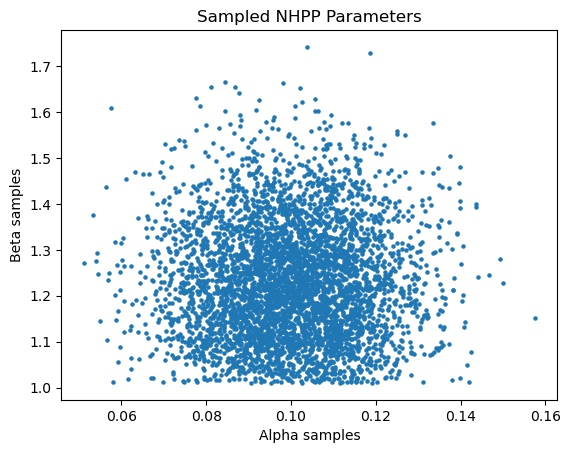

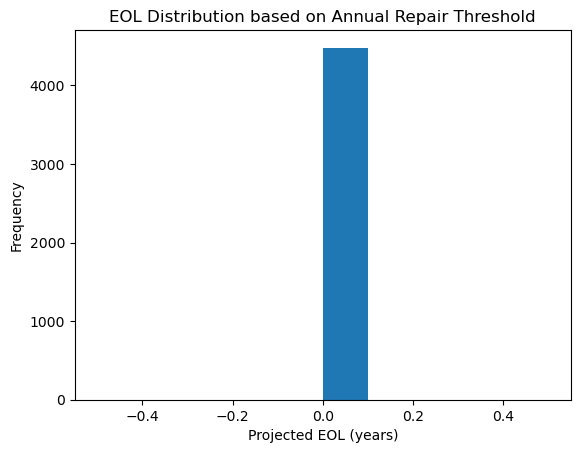

Mean EOL: 0.0
Median EOL: 0.0
95% CI: [0. 0.]


In [24]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

# repair times per year
repair_dates = [
    "2020-01-15",
    "2020-06-20",
    "2021-02-03",
    "2021-08-12",
    "2022-03-10"
]



# Convert to datetime
dates = pd.to_datetime(repair_dates)

# Compute time in years since first repair
t = (dates - dates.min()).total_seconds() / (365.25*24*3600)
T = t[-1]  # observation window end

def neg_log_likelihood(params):
    alpha, beta = params
    
    if alpha <= 0 or beta <= 0:
        return np.inf
    
    # intensity integral
    Lambda_T = alpha * T**beta
    
    # log likelihood
    ll = np.sum(np.log(alpha * beta * t**(beta-1))) - Lambda_T
    
    return -ll

res = minimize(neg_log_likelihood, x0=[0.1, 1.2])

alpha_hat, beta_hat = res.x

print("alpha:", alpha_hat)
print("beta:", beta_hat)


def hessian(func, params, eps=1e-5):
    n = len(params)
    hess = np.zeros((n, n))
    f0 = func(params)
    
    for i in range(n):
        for j in range(n):
            p = params.copy()
            p[i] += eps
            p[j] += eps
            f1 = func(p)
            
            p = params.copy()
            p[i] += eps
            f2 = func(p)
            
            p = params.copy()
            p[j] += eps
            f3 = func(p)
            
            hess[i, j] = (f1 - f2 - f3 + f0) / eps**2
            
    return hess

H = hessian(neg_log_likelihood, res.x)
print("Median EOL:", np.median(t_star))
print("95% CI:", np.percentile(t_star, [2.5, 97.5]))
print("Hessian at MLE:", H)



# Optional: sample uncertainty if desired
alpha_sd = 0.015
beta_sd = 0.15
samples = 5000

alpha_s = np.random.normal(alpha_hat, alpha_sd, samples)
beta_s  = np.random.normal(beta_hat, beta_sd, samples)

# Keep valid draws
mask = (alpha_s > 0) & (beta_s > 1.01)
alpha_s = alpha_s[mask]
beta_s = beta_s[mask]

# ---------------------------
# Define annual repair threshold
# ---------------------------
annual_repairs_crit = 5  # replace with your threshold

# ---------------------------
# Compute EOL for each sample
# ---------------------------
t_star = []
for a, b in zip(alpha_s, beta_s):
    # define a fine grid in time (e.g., quarterly steps)
    t_grid = np.linspace(0, 50, 5000)
    # expected repairs per year
    e_repairs = a * ((t_grid + 1)**b - t_grid**b)
    # find first t exceeding threshold
    exceed_idx = np.argmax(e_repairs >= annual_repairs_crit)
    t_star.append(t_grid[exceed_idx])

t_star = np.array(t_star)

# ---------------------------
# Plot parameter sampling
# ---------------------------
plt.figure()
plt.scatter(alpha_s, beta_s, s=5)
plt.xlabel("Alpha samples")
plt.ylabel("Beta samples")
plt.title("Sampled NHPP Parameters")
plt.show()

# ---------------------------
# Plot EOL distribution
# ---------------------------
plt.figure()
plt.hist(t_star)
plt.xlabel("Projected EOL (years)")
plt.ylabel("Frequency")
plt.title("EOL Distribution based on Annual Repair Threshold")
plt.show()

print("Mean EOL:", np.mean(t_star))
print("Median EOL:", np.median(t_star))
print("95% CI:", np.percentile(t_star, [2.5, 97.5]))

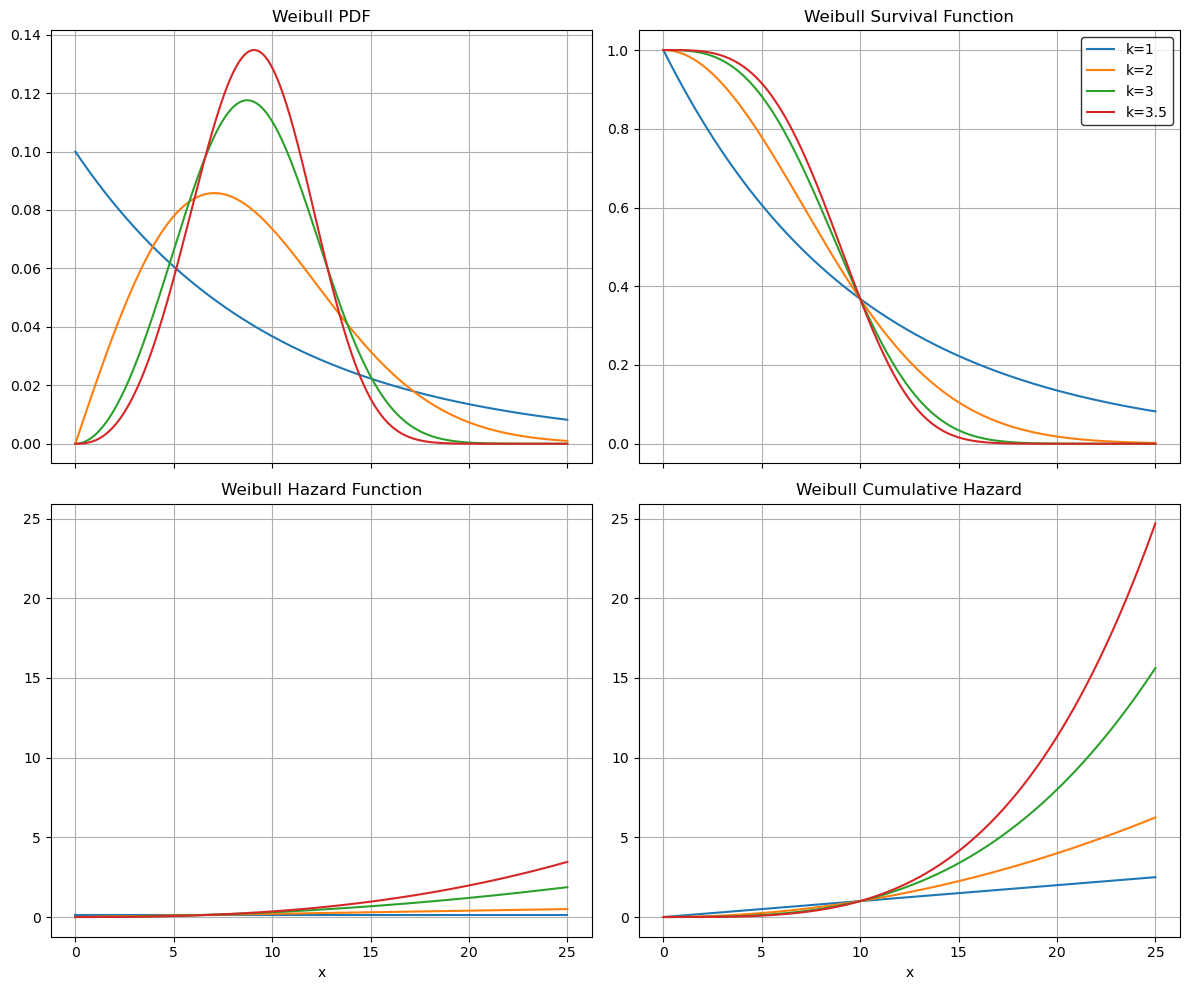

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------
# USER OPTIONS
# -----------------------
k_values = [1, 2, 3, 3.5]
lam = 10.0
use_log_scale = False
# -----------------------

x = np.linspace(0.001, 25, 1000)

# Make bottom row share y-axis
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [1,1]}
)

# Force bottom row to share y-axis
axes[1, 0].sharey(axes[1, 1])

for k in k_values:
    pdf = (k / lam) * (x / lam)**(k - 1) * np.exp(-(x / lam)**k)
    sf = np.exp(-(x / lam)**k)
    hazard = pdf / sf
    cum_hazard = (x / lam)**k

    axes[0, 0].plot(x, pdf, label=f"k={k}")
    axes[0, 1].plot(x, sf, label=f"k={k}")
    axes[1, 0].plot(x, hazard, label=f"k={k}")
    axes[1, 1].plot(x, cum_hazard, label=f"k={k}")

# Titles
axes[0, 0].set_title("Weibull PDF")
axes[0, 1].set_title("Weibull Survival Function")
axes[1, 0].set_title("Weibull Hazard Function")
axes[1, 1].set_title("Weibull Cumulative Hazard")

for ax in axes.flatten():
    ax.grid(True)
    #ax.legend()
    if use_log_scale:
        ax.set_yscale("log")


axes[1, 0].set_xlabel("x")
axes[1, 1].set_xlabel("x")
axes[0, 1].legend(loc='upper right', frameon=True, edgecolor='black') 

plt.tight_layout()
plt.savefig("weibull_functions.png", dpi=300)
plt.show()

C:\Users\Drew\AppData\Local\Temp\ipykernel_39532\4210813254.py:24: RuntimeWarning: divide by zero encountered in log
  return -np.sum(np.log(alpha * beta * t_data**(beta-1))) - alpha * t_data[-1]**beta
c:\Users\Drew\anaconda3\Lib\site-packages\scipy\optimize\_numdiff.py:686: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]
C:\Users\Drew\AppData\Local\Temp\ipykernel_39532\4210813254.py:24: RuntimeWarning: overflow encountered in power
  return -np.sum(np.log(alpha * beta * t_data**(beta-1))) - alpha * t_data[-1]**beta
c:\Users\Drew\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:88: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\Drew\AppData\Local\Temp\ipykernel_39532\4210813254.py:24: RuntimeWarning: overflow encountered in scalar power
  return -np.sum(np.log(alpha * beta * t_data**(beta-1))) - alpha * t_data[-1]**beta


MLE estimates: alpha = 8.03624478133046 , beta = 21.186138061208407


C:\Users\Drew\AppData\Local\Temp\ipykernel_39532\4210813254.py:56: RuntimeWarning: divide by zero encountered in log
  res = minimize(lambda p: -np.sum(np.log(p[0]*p[1]*sim**(p[1]-1))) + p[0]*sim[-1]**p[1],


Projected EOL (mean): 0.0
95% CI: 0.0 - 0.0


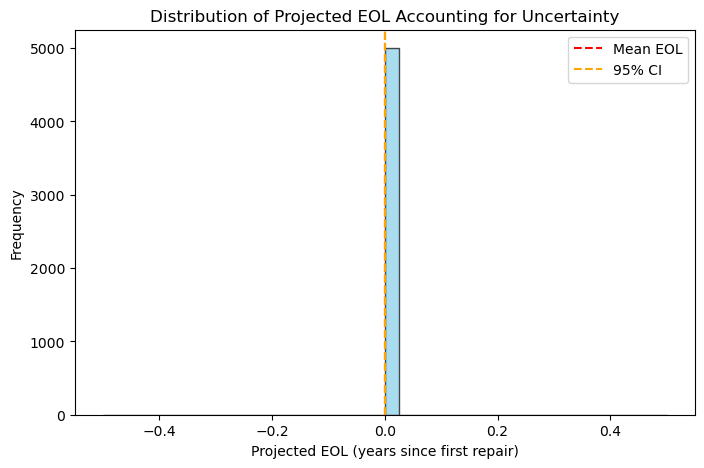

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize


def sim_repair_times(alpha, beta, n_events):
    U = np.random.uniform(0, 1, n_events)
    t_events = (-np.log(1 - U) / alpha)**(1 / beta)
    t_events = np.sort(t_events)
    start_date = pd.to_datetime("2020-01-01")
    return [start_date + pd.to_timedelta(t*365.25, unit='D') for t in t_events]

def dates_to_list(repair_dates):
    dates = pd.to_datetime(repair_dates)
    t =(dates - dates.min()).total_seconds() / (365.25*24*3600)
    return  np.array(t) + 1e-6


def neg_log_likelihood(params, t_data):
    alpha, beta = params
    if alpha <= 0 or beta <= 0:
        return np.inf
    return -np.sum(np.log(alpha * beta * t_data**(beta-1))) - alpha * t_data[-1]**beta

def fit_powerlaw_mle(t):
    bounds = ((1e-6, None), (1e-6, None))
    res = minimize(lambda p: neg_log_likelihood(p, t),
                x0=[1, 1.4],
                bounds=((1e-6,None),(1e-6,None)),
                method='L-BFGS-B')
    alpha_hat, beta_hat = res.x
    print("MLE estimates: alpha =", alpha_hat, ", beta =", beta_hat)
    return alpha_hat, beta_hat

repair_dates = sim_repair_times(alpha=0.1, beta=1.2, n_events=50)
t = dates_to_list(repair_dates)
alpha_hat, beta_hat = fit_powerlaw_mle(t)


# Measurement error (1 day)
t_measurements = 1/365

# MC for uncertainty propagation
samples = 5000
np.random.seed(42)

# Sample measurement error in repair times
t_sims = np.array([t + np.abs(np.random.normal(0, t_measurements, len(t))) for _ in range(samples)])

alpha_samples = []
beta_samples = []

for sim in t_sims:
    try:
        res = minimize(lambda p: -np.sum(np.log(p[0]*p[1]*sim**(p[1]-1))) + p[0]*sim[-1]**p[1],
                       x0=[alpha_hat, beta_hat], method='L-BFGS-B', bounds=((1e-6,None),(1e-6,None)))
        alpha_samples.append(res.x[0])
        beta_samples.append(res.x[1])
    except:
        continue

alpha_samples = np.array(alpha_samples)
beta_samples = np.array(beta_samples)

# Compute EOL
annual_repairs_crit = 1  # e.g., 2 repairs per year
t_EOL = []
years_to_project = 50

for a, b in zip(alpha_samples, beta_samples):
    # grid of times to check
    t_grid = np.linspace(0, years_to_project, 2000)  
    e_repairs = a * ((t_grid + 1)**b - t_grid**b)
    exceed_idx = np.argmax(e_repairs >= annual_repairs_crit)
    t_EOL.append(t_grid[exceed_idx])
t_EOL = np.array(t_EOL)
t_EOL = t_EOL[~np.isnan(t_EOL)]  # remove failed samples

# ---------------------------
# 6️⃣ Compute 95% confidence interval
# ---------------------------
ci_lower, ci_upper = np.percentile(t_EOL, [2.5, 97.5])
print("Projected EOL (mean):", np.mean(t_EOL))
print("95% CI:", ci_lower, "-", ci_upper)

# ---------------------------
# 7️⃣ Plot EOL distribution
# ---------------------------
plt.figure(figsize=(8,5))
plt.hist(t_EOL, bins=40, alpha=0.7, color='skyblue', edgecolor='k')
plt.axvline(np.mean(t_EOL), color='red', linestyle='--', label='Mean EOL')
plt.axvline(ci_lower, color='orange', linestyle='--', label='95% CI')
plt.axvline(ci_upper, color='orange', linestyle='--')
plt.xlabel("Projected EOL (years since first repair)")
plt.ylabel("Frequency")
plt.title("Distribution of Projected EOL Accounting for Uncertainty")
plt.legend()
plt.show()

In [9]:
print(neg_log_likelihood([0.1, 1.2], t))
print(neg_log_likelihood([0.2, 1.2], t))
print(neg_log_likelihood([0.1, 1.3], t))

97.66731296216847
83.80436935727914
123.69747991990164


Fitted Power Law NHPP parameters:
alpha = 231.88368748637822
beta = 1.4969105174639863
Projected EOL (years):
Mean = 1.0
Median = 1.0
95% CI = [1. 1.]


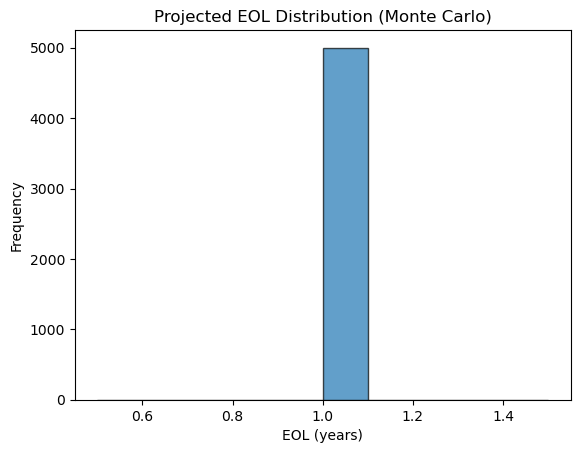

In [91]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# ------------------------
# 1. Simulate repair times
# ------------------------
def sim_repair_times(alpha, beta, n_events, start_date="2020-01-01"):
    """
    Generate NHPP repair dates from a Power Law NHPP.
    alpha, beta: Power Law parameters
    n_events: number of repair events to simulate
    """
    U = np.random.uniform(0, 1, n_events)
    t_events = (-np.log(1-U)/alpha)**(1/beta)
    t_events = np.sort(t_events)
    start_date = pd.to_datetime(start_date)
    repair_dates = [start_date + pd.to_timedelta(t*365.25, unit='D') for t in t_events]
    return repair_dates

# ------------------------
# 2. Convert dates -> numeric t
# ------------------------
def dates_to_numeric(repair_dates):
    dates = pd.to_datetime(repair_dates)
    t = (dates - dates.min()).total_seconds() / (365.25*24*3600)  # years
    t = np.array(t) + 1e-6  # avoid t=0
    return t

# ------------------------
# 3. Negative log-likelihood
# ------------------------
def neg_log_likelihood(params, t_data):
    alpha, beta = params
    if alpha <= 0 or beta <= 0:
        return np.inf
    T = t_data[-1]
    ll = np.sum(np.log(alpha * beta * t_data**(beta-1))) - alpha * T**beta
    return -ll

# ------------------------
# 4. Fit MLE
# ------------------------
def fit_power_law(t_data, x0=[0.05, 1.0]):
    res = minimize(lambda p: neg_log_likelihood(p, t_data),
                   x0=x0,
                   bounds=((1e-6,None),(1e-6,None)),
                   method='Nelder-Mead')
    alpha_hat, beta_hat = res.x
    return alpha_hat, beta_hat

# ------------------------
# 5. Monte Carlo EOL projection
# ------------------------
def project_EOL(alpha, beta, threshold=1.0, n_sim=1000, max_years=30):
    """
    Projects EOL as first year when annual repairs reach threshold.
    Returns array of projected EOLs from simulations.
    """
    EOLs = []
    for _ in range(n_sim):
        # simulate future NHPP events for 0..max_years
        t_future = []
        T_max = max_years
        while True:
            # inter-event time from Power Law NHPP inversion
            U = np.random.uniform()
            t_next = ((-np.log(1-U)/alpha)**(1/beta)) if len(t_future)==0 else t_future[-1] + ((-np.log(1-U)/alpha)**(1/beta))
            if t_next > T_max:
                break
            t_future.append(t_next)
        t_future = np.array(t_future)
        
        # compute annual counts
        if len(t_future)==0:
            EOLs.append(np.nan)
            continue
        years = np.floor(t_future)
        counts = [np.sum(years==y) for y in range(max_years)]
        # find first year with count >= threshold
        exceed = np.where(np.array(counts) >= threshold)[0]
        EOL = exceed[0]+1 if len(exceed)>0 else max_years
        EOLs.append(EOL)
    return np.array(EOLs)

# ------------------------
# 6. Run full example
# ------------------------
# Simulate repair dates
repair_dates = sim_repair_times(alpha=0.3, beta=10, n_events=100)
t = dates_to_numeric(repair_dates)

# Fit MLE
alpha_hat, beta_hat = fit_power_law(t)
print("Fitted Power Law NHPP parameters:")
print("alpha =", alpha_hat)
print("beta =", beta_hat)

# Project EOL
EOL_samples = project_EOL(alpha_hat, beta_hat, threshold=1.0, n_sim=5000, max_years=30)
EOL_samples = EOL_samples[~np.isnan(EOL_samples)]

# Summary statistics
print("Projected EOL (years):")
print("Mean =", np.mean(EOL_samples))
print("Median =", np.median(EOL_samples))
print("95% CI =", np.percentile(EOL_samples, [2.5, 97.5]))

# Plot distribution
plt.hist(EOL_samples, edgecolor='k', alpha=0.7)
plt.xlabel("EOL (years)")
plt.ylabel("Frequency")
plt.title("Projected EOL Distribution (Monte Carlo)")
plt.show()

212.77147414230615 0.4766169875073114


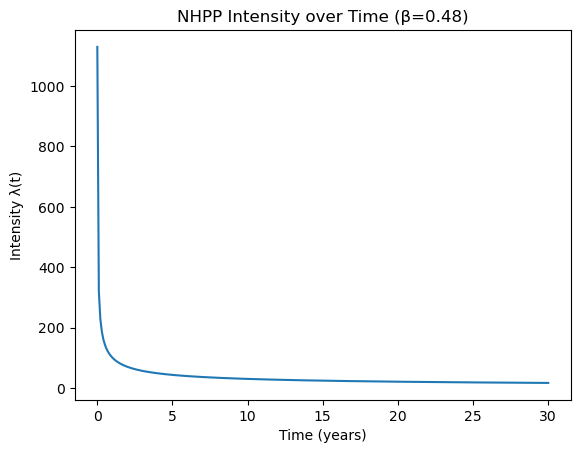

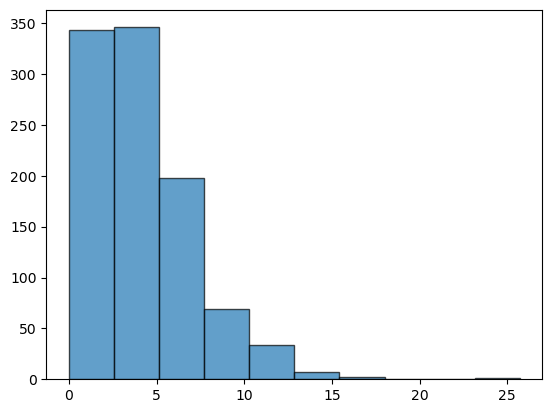

In [128]:
import matplotlib.pyplot as plt

repair_dates = sim_repair_times(alpha=0.1, beta=1.5, n_events=1000)
t = dates_to_numeric(repair_dates)

# Fit MLE
alpha_hat, beta_hat = fit_power_law(t)
print(alpha_hat, beta_hat)
t_vals = np.linspace(0.01, 30, 300)
lambda_t = alpha_hat * beta_hat * t_vals**(beta_hat-1)

plt.plot(t_vals, lambda_t)
plt.xlabel("Time (years)")
plt.ylabel("Intensity λ(t)")
plt.title(f"NHPP Intensity over Time (β={beta_hat:.2f})")
plt.show()

plt.hist(t, edgecolor='k', alpha=0.7)
plt.show()

Fitted analytic MLE parameters:
alpha = 183.32829655373334
beta = 0.618709115438563


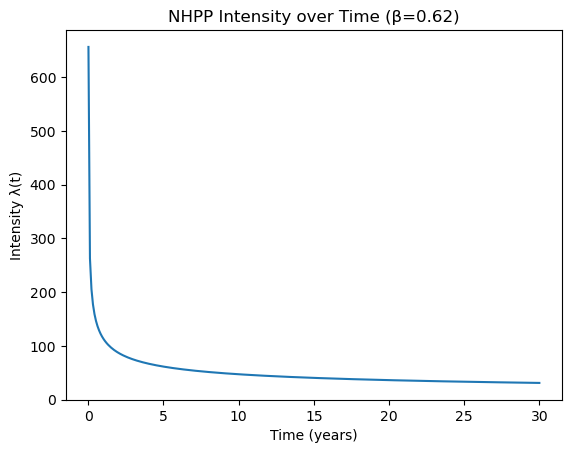

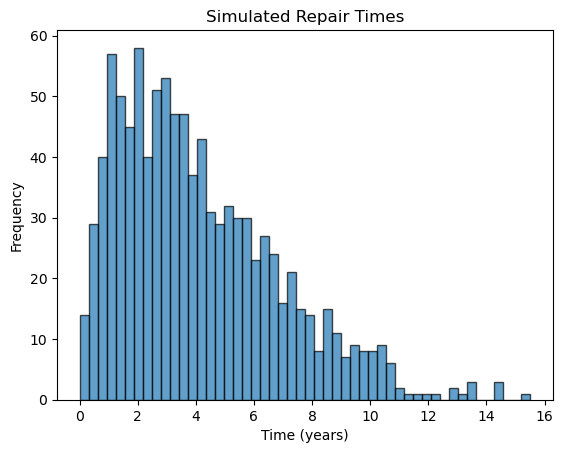

KeyboardInterrupt: 

In [144]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------
# 1. Simulate repair times
# ------------------------
def sim_repair_times_fixed_T(alpha, beta, T=30):
    """
    Simulate NHPP events over time window [0,T] using correct conditional distribution.
    """
    # Total number of events
    Lambda_T = alpha * T**beta
    n_events = np.random.poisson(Lambda_T)
    
    # Sample event times using the conditional distribution
    if n_events == 0:
        return []

    U = np.random.uniform(0, 1, n_events)
    t_events = T * U**(1/beta)  # Inverse CDF of t^β/T^β distribution
    t_events = np.sort(t_events)
    start_date = pd.to_datetime("2020-01-01")
    repair_dates = [start_date + pd.to_timedelta(t*365.25, unit='D') for t in t_events]
    return repair_dates

# ------------------------
# 2. Convert dates -> numeric t
# ------------------------
def dates_to_numeric(repair_dates):
    dates = pd.to_datetime(repair_dates)
    t = (dates - dates.min()).total_seconds() / (365.25*24*3600)  # years
    t = np.array(t) + 1e-6  # avoid t=0
    return t

# ------------------------
# 3. Analytic MLE for Power Law NHPP
# ------------------------
def analytic_mle_power_law(t_data):
    T = t_data[-1]
    n = len(t_data)
    beta_hat = n / np.sum(np.log(T / t_data))
    alpha_hat = n / (T ** beta_hat)
    return alpha_hat, beta_hat

# ------------------------
# 4. Monte Carlo EOL projection
# ------------------------
def project_EOL(alpha, beta, threshold=1.0, n_sim=1000, max_years=30):
    EOLs = []
    for _ in range(n_sim):
        t_future = []
        T_max = max_years
        while True:
            U = np.random.uniform()
            t_next = ((-np.log(1-U)/alpha)**(1/beta)) if len(t_future)==0 else t_future[-1] + ((-np.log(1-U)/alpha)**(1/beta))
            if t_next > T_max:
                break
            t_future.append(t_next)
        t_future = np.array(t_future)
        if len(t_future)==0:
            EOLs.append(np.nan)
            continue
        years = np.floor(t_future)
        counts = [np.sum(years==y) for y in range(max_years)]
        exceed = np.where(np.array(counts) >= threshold)[0]
        EOL = exceed[0]+1 if len(exceed)>0 else max_years
        EOLs.append(EOL)
    return np.array(EOLs)

# ------------------------
# 5. Run full example
# ------------------------
# Simulate repair dates
repair_dates = sim_repair_times(alpha=0.1, beta=1.5, n_events=1000)
t = dates_to_numeric(repair_dates)

# Analytic MLE
alpha_hat, beta_hat = analytic_mle_power_law(t)
print("Fitted analytic MLE parameters:")
print("alpha =", alpha_hat)
print("beta =", beta_hat)

# Plot intensity
t_vals = np.linspace(0.01, 30, 300)
lambda_t = alpha_hat * beta_hat * t_vals**(beta_hat-1)
plt.plot(t_vals, lambda_t)
plt.xlabel("Time (years)")
plt.ylabel("Intensity λ(t)")
plt.title(f"NHPP Intensity over Time (β={beta_hat:.2f})")
plt.show()

# Histogram of event times
plt.hist(t, bins=50, edgecolor='k', alpha=0.7)
plt.xlabel("Time (years)")
plt.ylabel("Frequency")
plt.title("Simulated Repair Times")
plt.show()

# Project EOL via Monte Carlo
EOL_samples = project_EOL(alpha_hat, beta_hat, threshold=1.0, n_sim=5000, max_years=30)
EOL_samples = EOL_samples[~np.isnan(EOL_samples)]

print("Projected EOL (years):")
print("Mean =", np.mean(EOL_samples))
print("Median =", np.median(EOL_samples))
print("95% CI =", np.percentile(EOL_samples, [2.5, 97.5]))

# Plot EOL distribution
plt.hist(EOL_samples, bins=np.arange(0,31)-0.5, edgecolor='k', alpha=0.7)
plt.xlabel("EOL (years)")
plt.ylabel("Frequency")
plt.title("Projected EOL Distribution (Monte Carlo)")
plt.show()

Fitted analytic MLE parameters:
alpha = 1.1588969567951044
beta = 1.3456832520323478


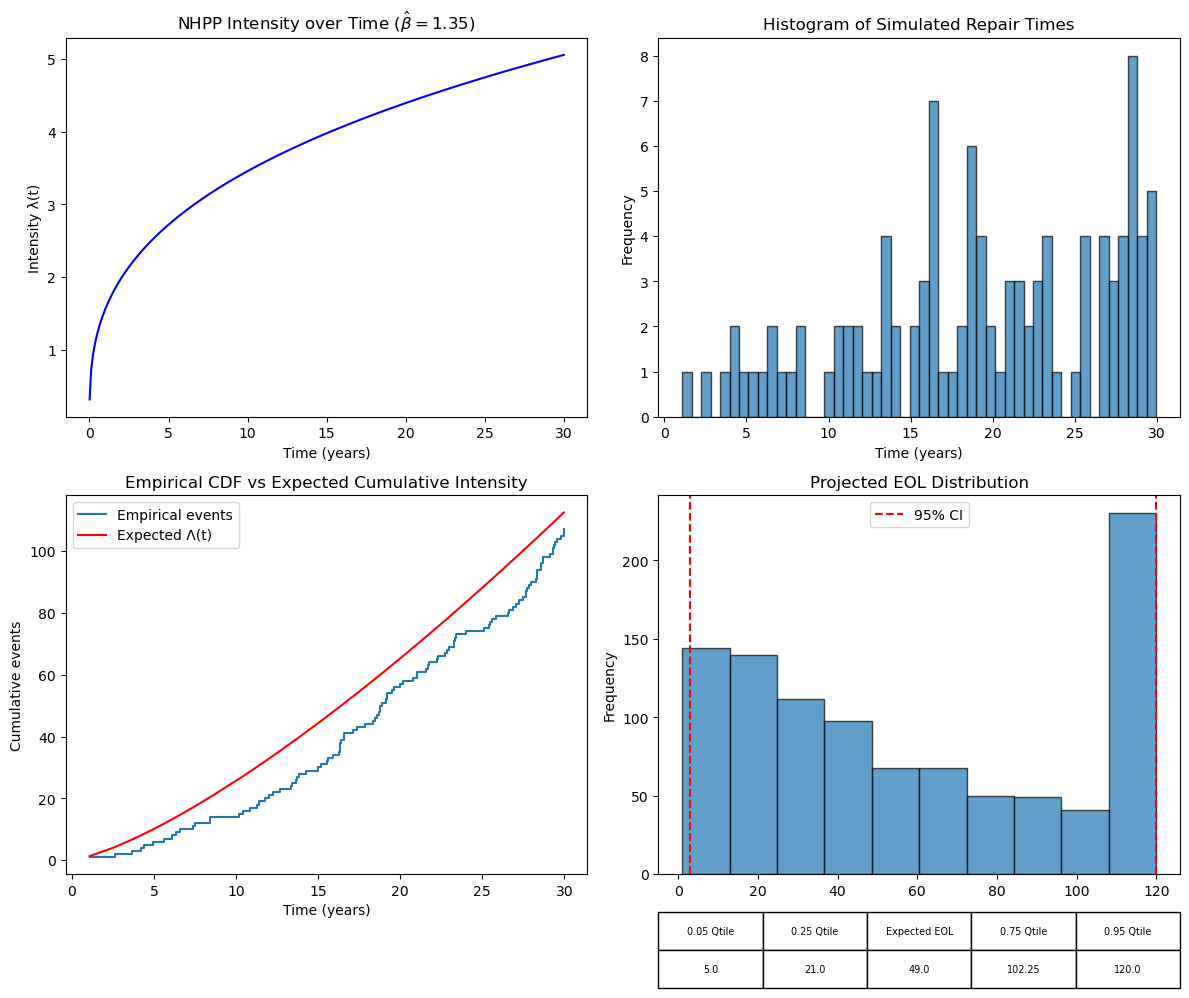

In [ ]:
# Simulate Repair Times via Thinning
def sim_nhpp_thinning(alpha, beta, T=30):
    """
    Simulate Power Law NHPP via thinning.
    """
    t_events = []
    lambda_max = alpha * beta * T**(beta-1)
    t = 0
    while t < T:
        # propose next event from homogeneous Poisson
        t += np.random.exponential(1/lambda_max)
        if t >= T:
            break
        # accept with probability lambda(t)/lambda_max
        if np.random.uniform() <= alpha*beta*t**(beta-1)/lambda_max:
            t_events.append(t)
    # convert to calendar dates
    start_date = pd.to_datetime("2020-01-01")
    repair_dates = [start_date + pd.to_timedelta(te*365.25, unit='D') for te in t_events]
    return repair_dates

# Date to Numeric conversion
def dates_to_numeric(repair_dates):
    dates = pd.to_datetime(repair_dates)
    t = (dates - dates.min()).total_seconds() / (365.25*24*3600)  # years
    t = np.array(t) + 1e-6  # avoid t=0
    return t

# MLE solution for the Power Function 
def analytic_mle_power_law(t_data):
    T = t_data[-1]
    n = len(t_data)
    beta_hat = n / np.sum(np.log(T / t_data))
    alpha_hat = n / (T ** beta_hat)
    return alpha_hat, beta_hat

# Monte Carlo EOL projection
def project_EOL(alpha, beta, threshold=1.0, n_sim=1000, max_years=30):
    EOLs = []
    for _ in range(n_sim):
        t_future = []
        T_max = max_years
        while True:
            U = np.random.uniform()
            t_next = ((-np.log(1-U)/alpha)**(1/beta)) if len(t_future)==0 else t_future[-1] + ((-np.log(1-U)/alpha)**(1/beta))
            if t_next > T_max:
                break
            t_future.append(t_next)
        t_future = np.array(t_future)
        if len(t_future)==0:
            EOLs.append(np.nan)
            continue
        years = np.floor(t_future)
        counts = [np.sum(years==y) for y in range(max_years)]
        exceed = np.where(np.array(counts) >= threshold)[0]
        EOL = exceed[0]+1 if len(exceed)>0 else max_years
        EOLs.append(EOL)
    return np.array(EOLs)

repair_dates = sim_nhpp_thinning(alpha=0.3, beta=1.7, T=30)
t = dates_to_numeric(repair_dates)

# Analytic MLE
t_scaled = t / t.max()
alpha_hat_scaled, beta_hat = analytic_mle_power_law(t_scaled)
alpha_hat = alpha_hat_scaled / t.max()**beta_hat
print("Fitted analytic MLE parameters:")
print("alpha =", alpha_hat)
print("beta =", beta_hat)

# Project EOL via Monte Carlo
EOL_samples = project_EOL(alpha_hat, beta_hat, threshold=4.0, n_sim=1000, max_years=4*T)
EOL_samples = EOL_samples[~np.isnan(EOL_samples)]

# Compute percentiles for table
percentiles = [5, 25, 50, 75, 95]
eol_summary = np.percentile(EOL_samples, percentiles)
col_labels = ["0.05 Qtile", "0.25 Qtile", "Expected EOL", "0.75 Qtile", "0.95 Qtile"]

# Numeric times
t_numeric = np.array([(d - pd.to_datetime("2020-01-01")).days/365.25 for d in repair_dates])
t_sorted = np.sort(t_numeric)

# Prepare intensity curve
t_vals = np.linspace(0.01, 30, 300)
lambda_t = alpha_hat * beta_hat * t_vals**(beta_hat-1)
Lambda_t = alpha_hat * t_sorted**beta_hat  # cumulative intensity
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
# Intensity lambda(t)
axes[0,0].plot(t_vals, lambda_t, color='blue')
axes[0,0].set_xlabel("Time (years)")
axes[0,0].set_ylabel("Intensity λ(t)")
axes[0,0].set_title(r"NHPP Intensity over Time ($\hat{{\beta}}=$"f"{beta_hat:.2f})")

# Histogram of simulated event times
axes[0,1].hist(t_numeric, bins=50, edgecolor='k', alpha=0.7)
axes[0,1].set_xlabel("Time (years)")
axes[0,1].set_ylabel("Frequency")
axes[0,1].set_title("Histogram of Simulated Repair Times")

# Empirical cumulative events vs expected Lambda(t)
axes[1,0].step(t_sorted, np.arange(1, len(t_sorted)+1), where='post', label="Empirical events")
axes[1,0].plot(t_sorted, Lambda_t, label=f"Expected $\Lambda(t)$", color='red')
axes[1,0].set_xlabel("Time (years)")
axes[1,0].set_ylabel("Cumulative events")
axes[1,0].set_title("Empirical CDF vs Expected Cumulative Intensity")
axes[1,0].legend()

# EOL projection histogram with 95% CI
axes[1,1].hist(EOL_samples, edgecolor='k', alpha=0.7)
ci_lower, ci_upper = np.percentile(EOL_samples, [2.5, 97.5])
axes[1,1].axvline(ci_lower, color='red', linestyle='--', label="95% CI")
axes[1,1].axvline(ci_upper, color='red', linestyle='--')
axes[1,1].set_title("Projected EOL Summary (years)")
axes[1,1].set_ylabel("Frequency")
axes[1,1].set_title("Projected EOL Distribution")
axes[1,1].legend()
table_data = [eol_summary]
table = axes[1,1].table(cellText=table_data, colLabels=col_labels, cellLoc='center', 
                  loc='bottom', bbox=[0.0, -0.3, 1, 0.2])  # x0,y0,width,height

plt.tight_layout()
plt.savefig("nhpp_eol_analysis.png", dpi=300)
plt.show()

In [184]:
EOL_samples = project_EOL(alpha_hat, beta_hat, threshold=5.0, n_sim=500, max_years=4*T)
EOL_samples = EOL_samples[~np.isnan(EOL_samples)]
EOL_samples

array([ 20,  47,  23,  12,  28,  12,  17,  55,  66,  34,  15,  20,  50,
        18,  46,  94,  13,  31,   4,   6,  10,   6,  21,  14,  28,  78,
        33,  49, 115,  14,  13,  40,  38,  22,  37,   2,  37,  15,   9,
         3,  21,  31,  17,   6,   7,  19,   1,   7,   6,  28,   7,  25,
         5,   7,  31,  75,  56,  39,  14,  62,  40,  49,  52,   5,  23,
        11, 103,  69,   6,  65,  17,   1,  30,  43,   1,  50,  10,   1,
        19,  37,  32, 120,   7,  95,   3,  22,  29,  63,  24, 102,   3,
        18,   3,  16,  59,  16,  56,  14,  37,  69,  21,   8,   8,  23,
        13,   6,  36,  43,  20,  13,   6,   2,  11,  40,  18,   7,   1,
         3,  56,  15,  81,  18,   2,  26,  16,  62,  22,  63,  69,   1,
         1,  19,  19,  29,  85,   6,  43,  64,  46,   4,  23,  20,  22,
        16,  32,  55,  59,   7,  77,  41,  13,  23,  33,  40,  10,  19,
        57,  74,  45,  81,  15,   9,  39,  12,   8,  30,  16,  75,  23,
         1,  20,   3,   4,  85,  30,  21,  14,   4,  15,  51,  5

In [152]:
alpha = 0.1
T = 30

for beta_sim in [1.5, 1.55, 1.6]:
    repair_dates = sim_repair_times_fixed_T(alpha, beta_sim, T=T)
    t = dates_to_numeric(repair_dates)
    alpha_hat, beta_hat = analytic_mle_power_law(t)
    print(f"Simulated beta={beta_sim}, Fitted beta_hat={beta_hat:.3f}")

Simulated beta=1.5, Fitted beta_hat=0.526
Simulated beta=1.55, Fitted beta_hat=0.711
Simulated beta=1.6, Fitted beta_hat=0.837


In [1]:
alpha_hat, beta_hat, t_last = 1.1588969567951044, 1.3456832520323478, 49
t_future = np.linspace(49, 49 + 20, 200)
Lambda_future = alpha_hat * t_future**beta_hat
Lambda_now = alpha_hat * t_last**beta_hat
expected_new_failures = Lambda_future - Lambda_now
plt.plot(t_future, expected_new_failures)
plt.xlabel("Time (years)")
plt.ylabel("Expected additional failures")
plt.title("Projected Future Failures")
plt.show()

years = np.arange(int(t_last), int(t_last)+20)
expected_yearly = alpha_hat*((years+1)**beta_hat - years**beta_hat)

plt.plot(years, expected_yearly)
plt.xlabel("Year")
plt.ylabel("Expected failures in year")
plt.title("Expected Annual Failures")
plt.show()

n_sim = 1000
time_grid = np.linspace(t_last, t_last+20, 100)
sim_paths = np.zeros((n_sim, len(time_grid)))

for i in range(n_sim):
    # simulate full NHPP path up to max(time_grid)
    t_sim = sim_nhpp_thinning(alpha_hat, beta_hat, max(time_grid))
    t_sim = dates_to_numeric(t_sim)  # convert to numeric
    
    for j, t_val in enumerate(time_grid):
        sim_paths[i, j] = np.sum(t_sim <= t_val)

lower = np.percentile(sim_paths, 5, axis=0)
upper = np.percentile(sim_paths, 95, axis=0)
mean_path = np.mean(sim_paths, axis=0)

plt.plot(time_grid, mean_path, label="Mean projection")
plt.fill_between(time_grid, lower, upper, alpha=0.3, label="95% band")
plt.title("Projected Cumulative Failures with Uncertainty")
plt.xlabel("Time (years)")
plt.ylabel("Cumulative failures")
plt.legend()
plt.savefig("nhpp_projection_uncertainty.png", dpi=300)
plt.show()

NameError: name 'np' is not defined